<a href="https://colab.research.google.com/github/priyanga2004113-coder/Startup-Investment-Analytics/blob/main/_Startup_Investment_Analytics_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Startup Investment Analytics
Dataset: https://www.kaggle.com/datasets/vagdevititikshag/indian-startup-funding-dataset-20202025?utm_source=chatgpt.com

In [ ]:
# ============================================
# 1. IMPORT LIBRARIES
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ============================================
# 2. LOAD DATASET
# ============================================

df = pd.read_csv('/content/indian_startup_funding_2020_2025_sample.csv')

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (1100, 8)

Columns:
['Startup', 'Industry', 'SubVertical', 'City', 'Investors', 'InvestmentType', 'InvestmentAmount_USD', 'Date']

First 5 Rows:


,Startup,Industry,SubVertical,City,Investors,InvestmentType,InvestmentAmount_USD,Date
0,Housejoy,EdTech,K12,Mumbai,Lightspeed India,Seed,199000,19-04-2023
1,Groww,Media,Streaming,Bengaluru,IFC,Seed,1668000,28-01-2025
2,Groww,Mobility,Ride Sharing,Hyderabad,"Nexus Venture Partners, Peak XV",Series B,38052000,14-03-2021
3,FarmBox,Consumer Electronics,Wearables,Gurugram,"Kalaari Capital, Y Combinator",Seed,455000,11-09-2023
4,Udaan,RealEstate,Rental Tech,Mumbai,Bessemer Venture Partners,Seed,89000,31-01-2024


In [ ]:
# ============================================
# 3. CHECK DATA TYPES
# ============================================

print(df.dtypes)

Startup                 object
Industry                object
SubVertical             object
City                    object
Investors               object
InvestmentType          object
InvestmentAmount_USD     int64
Date                    object
dtype: object


In [ ]:
# ============================================
# 4. CHECK MISSING VALUES
# ============================================

missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:
Startup                 0
Industry                0
SubVertical             0
City                    0
Investors               0
InvestmentType          0
InvestmentAmount_USD    0
Date                    0
dtype: int64

Total Missing Values: 0


In [ ]:
# ============================================
# 5. CHECK DUPLICATE VALUES
# ============================================

duplicates = df.duplicated().sum()

print("Duplicate Rows:", duplicates)

Duplicate Rows: 0


In [ ]:
# ============================================
# 6. REMOVE DUPLICATES
# ============================================

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (1100, 8)


In [ ]:
# ============================================
# 7. CLEAN TEXT COLUMNS
# ============================================

text_columns = [
    'Startup',
    'Industry',
    'SubVertical',
    'City',
    'Investors',
    'InvestmentType'
]

for col in text_columns:
    df[col] = df[col].astype(str).str.strip()

print("Text cleaning completed.")

Text cleaning completed.


In [ ]:
# ============================================
# 8. HANDLE MISSING / UNKNOWN TEXT VALUES
# ============================================

for col in text_columns:
    df[col] = df[col].replace(
        ['nan', 'NaN', '', 'Unknown', 'unknown'],
        'Unknown'
    )

print("Unknown values handled.")

Unknown values handled.


In [ ]:
# ============================================
# 9. CONVERT INVESTMENT AMOUNT TO NUMERIC
# ============================================

df['InvestmentAmount_USD'] = pd.to_numeric(
    df['InvestmentAmount_USD'],
    errors='coerce'
)

print(df['InvestmentAmount_USD'].dtype)

int64


In [ ]:
# ============================================
# 10. HANDLE INVALID INVESTMENT AMOUNTS
# ============================================

# Negative investment amounts are invalid
df.loc[df['InvestmentAmount_USD'] < 0, 'InvestmentAmount_USD'] = np.nan

# Remove rows where investment amount is missing
df = df.dropna(subset=['InvestmentAmount_USD'])

print("Rows after amount cleaning:", df.shape)

Rows after amount cleaning: (1100, 8)


In [ ]:
# ============================================
# 11. CONVERT DATE COLUMN
# ============================================

df['Date'] = pd.to_datetime(
    df['Date'],
    dayfirst=True,
    errors='coerce'
)

print(df['Date'].dtype)
print("Invalid Dates:", df['Date'].isna().sum())

datetime64[ns]
Invalid Dates: 0


In [ ]:
# ============================================
# 12. CREATE YEAR AND MONTH COLUMNS
# ============================================

df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['MonthName'] = df['Date'].dt.month_name()

print(df[['Date', 'Year', 'Month', 'MonthName']].head())

        Date  Year  Month  MonthName
0 2023-04-19  2023      4      April
1 2025-01-28  2025      1    January
2 2021-03-14  2021      3      March
3 2023-09-11  2023      9  September
4 2024-01-31  2024      1    January


In [ ]:
# ============================================
# 13. OUTLIER DETECTION USING IQR
# ============================================

Q1 = df['InvestmentAmount_USD'].quantile(0.25)
Q3 = df['InvestmentAmount_USD'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 169750.0
Q3: 10172500.0
IQR: 10002750.0
Lower Bound: -14834375.0
Upper Bound: 25176625.0


In [ ]:
# ============================================
# 14. CREATE OUTLIER FLAG
# ============================================

df['Outlier'] = np.where(
    (df['InvestmentAmount_USD'] < lower_bound) |
    (df['InvestmentAmount_USD'] > upper_bound),
    'Yes',
    'No'
)

print(df['Outlier'].value_counts())

Outlier
No     904
Yes    196
Name: count, dtype: int64


In [ ]:
# ============================================
# 15. CHECK OUTLIER AMOUNTS
# ============================================

outliers = df[df['Outlier'] == 'Yes']

print("Number of Outliers:", len(outliers))

display(
    outliers[
        [
            'Startup',
            'Industry',
            'InvestmentAmount_USD',
            'InvestmentType',
            'Investors',
            'Date'
        ]
    ].sort_values(
        'InvestmentAmount_USD',
        ascending=False
    ).head(20)
)

Number of Outliers: 196


,Startup,Industry,InvestmentAmount_USD,InvestmentType,Investors,Date
1015,CoreSpace,EdTech,574676000.0,Growth,"Kalaari Capital, Y Combinator",2024-02-04
825,BharatPe,Consumer Electronics,566555000.0,Growth,"IFC, Kalaari Capital, Sequoia Capital India",2024-04-19
273,Bounce,AgriTech,556750000.0,Growth,Kalaari Capital,2020-01-26
197,NextSense,Mobility,533548000.0,Growth,Accel,2022-10-15
7,FinSpace,Consumer Electronics,491721000.0,Growth,Blume Ventures,2025-01-22
1088,FreshToHome,SaaS,489935000.0,Series D,Elevation Capital,2024-10-22
932,HomeFoods,Media,482361000.0,Series D,"Omidyar Network, Prosus Ventures",2020-02-17
464,AgriSense,Retail,458292000.0,Series D,"A91 Partners, Bessemer Venture Partners",2021-09-08
507,Paytm,Mobility,438231000.0,Growth,"Info Edge, Peak XV",2023-11-29
618,GrowthConnect,Consumer Electronics,419740000.0,Growth,"Falcon Edge, Tiger Global Management",2021-05-18


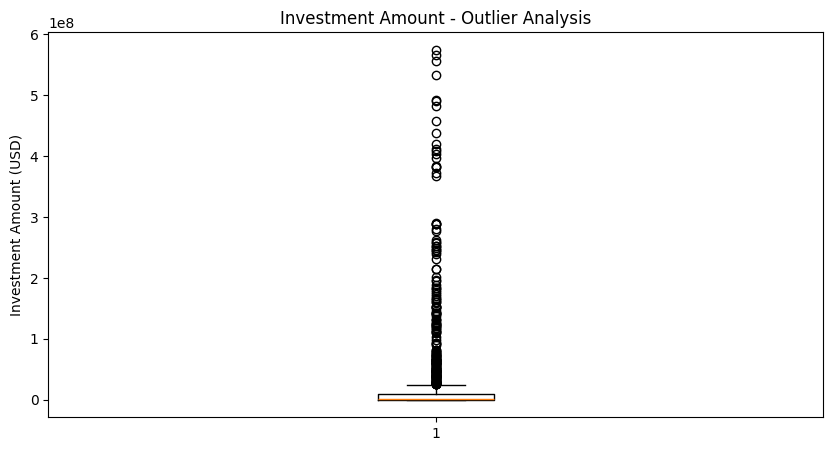

In [ ]:
# ============================================
# 16. BOXPLOT BEFORE TREATMENT
# ============================================

plt.figure(figsize=(10, 5))

plt.boxplot(df['InvestmentAmount_USD'])

plt.title('Investment Amount - Outlier Analysis')
plt.ylabel('Investment Amount (USD)')

plt.show()

In [ ]:
# ============================================
# 17. FINAL DATA QUALITY CHECK
# ============================================

print("Final Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

print("\nOutlier Count:")
print(df['Outlier'].value_counts())

Final Shape: (1100, 12)

Missing Values:
Startup                 0
Industry                0
SubVertical             0
City                    0
Investors               0
InvestmentType          0
InvestmentAmount_USD    0
Date                    0
Year                    0
Month                   0
MonthName               0
Outlier                 0
dtype: int64

Duplicate Rows: 0

Data Types:
Startup                         object
Industry                        object
SubVertical                     object
City                            object
Investors                       object
InvestmentType                  object
InvestmentAmount_USD           float64
Date                    datetime64[ns]
Year                             int32
Month                            int32
MonthName                       object
Outlier                         object
dtype: object

Outlier Count:
Outlier
No     904
Yes    196
Name: count, dtype: int64


In [ ]:
# ============================================
# 18. SAVE CLEANED DATASET
# ============================================

output_file = '/content/startup_investment_cleaned.csv'

df.to_csv(
    output_file,
    index=False
)

print("Cleaned dataset saved successfully!")
print(output_file)

Cleaned dataset saved successfully!
/content/startup_investment_cleaned.csv
